In [1]:
# ============================================================
# Import Libraries
# ============================================================

import os
import json
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import numpy as np
import time
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score)
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# # ============================================================
# # Project Directory
# # ============================================================
  
PROJECT_DIR = "D:/Brac_thesis"

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "dataset"
)

PROCESSED_DATASET_DIR = os.path.join(
    DATASET_DIR,
    "processed"
)

METADATA_DIR = os.path.join(
    DATASET_DIR,
    "metadata"
)

In [3]:
# # ============================================================
# # Dataset Files
# # ============================================================

TRAIN_CSV = os.path.join(
    PROCESSED_DATASET_DIR,
    "train.csv"
)

VALIDATION_CSV = os.path.join(
    PROCESSED_DATASET_DIR,
    "validation.csv"
)

TEST_CSV = os.path.join(
    PROCESSED_DATASET_DIR,
    "test.csv"
)

METADATA_PATH = os.path.join(
    METADATA_DIR,
    "metadata.json"
)

print("Dataset Paths Ready")

Dataset Paths Ready


In [4]:
# ============================================================
# Section 2 : Project Paths
# ============================================================

MODELS_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

# ============================================================
# Results Directory
# ============================================================

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "comparison"
)

CONFUSION_MATRIX_DIR = os.path.join(
    RESULTS_DIR,
    "confusion_matrices"
)

ROC_CURVE_DIR = os.path.join(
    RESULTS_DIR,
    "roc_curves"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

# ============================================================
# Create Directories
# ============================================================

for directory in [

    RESULTS_DIR,

    CONFUSION_MATRIX_DIR,

    ROC_CURVE_DIR,

    METRICS_DIR

]:

    os.makedirs(

        directory,

        exist_ok=True

    )

print("Project Paths Ready")

Project Paths Ready


In [5]:
# ============================================================
# Section 3 : Load Metadata
# ============================================================

with open(

    METADATA_PATH,

    "r"

) as file:

    metadata = json.load(

        file

    )

# ============================================================
# Image Information
# ============================================================

IMAGE_HEIGHT = metadata["image_height"]

IMAGE_WIDTH = metadata["image_width"]

CHANNELS = metadata["channels"]

# ============================================================
# Dataset Information
# ============================================================

TRAIN_SIZE = metadata["train_size"]

VALIDATION_SIZE = metadata["validation_size"]

TEST_SIZE = metadata["test_size"]

TOTAL_IMAGES = metadata["total_images"]

NUM_CLASSES = metadata["total_labels"]

# ============================================================
# Label Information
# ============================================================

CLASS_NAMES = metadata["labels"]

LABEL_TO_INDEX = metadata["label_to_index"]

INDEX_TO_LABEL = {

    int(index): label

    for index, label in metadata["index_to_label"].items()

}

# ============================================================
# Display Metadata
# ============================================================

print(f"Image Size        : {IMAGE_HEIGHT} × {IMAGE_WIDTH}")

print(f"Channels          : {CHANNELS}")

print(f"Training Split    : {TRAIN_SIZE:.0%}")

print(f"Validation Split  : {VALIDATION_SIZE:.0%}")

print(f"Testing Split     : {TEST_SIZE:.0%}")

print(f"Total Images      : {TOTAL_IMAGES}")

print(f"Total Classes     : {NUM_CLASSES}")

print()

print("Class Labels")

print("-" * 40)

for index, label in INDEX_TO_LABEL.items():

    print(f"{index:2d} : {label}")

print()

print("Metadata Loaded Successfully")

Image Size        : 224 × 224
Channels          : 3
Training Split    : 80%
Validation Split  : 10%
Testing Split     : 10%
Total Images      : 8275
Total Classes     : 12

Class Labels
----------------------------------------
 0 : Acne_Mild
 1 : Acne_Moderate
 2 : Acne_Severe
 3 : Eczema_Mild
 4 : Eczema_Moderate
 5 : Eczema_Severe
 6 : Normal_dry
 7 : Normal_normal
 8 : Normal_oily
 9 : burn_Mild
10 : burn_Moderate
11 : burn_Severe

Metadata Loaded Successfully


In [6]:
# ============================================================
# Section 4 : Load Test Dataset
# ============================================================

test_df = pd.read_csv(

    TEST_CSV

)

print(

    f"Total Test Images : {len(test_df)}"

)

# ============================================================
# Image Loading Function
# ============================================================

def load_image(

    image_path,

    label

):

    image = tf.io.read_file(

        image_path

    )

    image = tf.io.decode_image(

        image,

        channels=CHANNELS,

        expand_animations=False

    )

    image = tf.image.resize(

        image,

        (

            IMAGE_HEIGHT,

            IMAGE_WIDTH

        )

    )

    image = tf.cast(

        image,

        tf.float32

    )

    label = tf.one_hot(

        label,

        depth=NUM_CLASSES,

        dtype=tf.float32

    )

    return image, label

print("Image Loader Ready")

# ============================================================
# Prepare Test Dataset
# ============================================================

test_dataset = tf.data.Dataset.from_tensor_slices(

    (

        test_df["filepath"].values,

        test_df["label"].map(

            LABEL_TO_INDEX

        ).values

    )

)

test_dataset = test_dataset.map(

    load_image,

    num_parallel_calls=tf.data.AUTOTUNE

)

test_dataset = test_dataset.batch(

    32

)

test_dataset = test_dataset.prefetch(

    tf.data.AUTOTUNE

)

print("Test Dataset Ready")

Total Test Images : 828
Image Loader Ready
Test Dataset Ready


In [7]:
# ============================================================
# Section 5 : Load Models
# ============================================================

models = {}

for model_folder in sorted(

    os.listdir(

        MODELS_DIR

    )

):

    model_folder_path = os.path.join(

        MODELS_DIR,

        model_folder

    )

    if not os.path.isdir(

        model_folder_path

    ):

        continue

    for split_folder in sorted(

        os.listdir(

            model_folder_path

        )

    ):

        split_folder_path = os.path.join(

            model_folder_path,

            split_folder

        )

        if not os.path.isdir(

            split_folder_path

        ):

            continue

        model_files = [

            file

            for file in os.listdir(

                split_folder_path

            )

            if file.startswith(

                "skin_condition_identifier"

            )

            and file.endswith(

                ".keras"

            )

        ]

        if not model_files:

            continue

        model_path = os.path.join(

            split_folder_path,

            model_files[0]

        )

        model_name = f"{model_folder}_{split_folder}"

        models[model_name] = keras.models.load_model(

            model_path

        )

        print(

            f"Loaded : {model_name}"

        )

print()

print(

    f"Total Models Loaded : {len(models)}"

)

Loaded : efficientnetb0_60_20_20
Loaded : efficientnetb0_70_15_15
Loaded : efficientnetb0_80_10_10
Loaded : efficientnetb0_90_5_5
Loaded : mobilenetv2_60_20_20
Loaded : mobilenetv2_70_15_15
Loaded : mobilenetv2_80_10_10
Loaded : mobilenetv2_90_5_5
Loaded : resnet50_60_20_20
Loaded : resnet50_70_15_15
Loaded : resnet50_80_10_10
Loaded : resnet50_90_5_5

Total Models Loaded : 12


In [8]:
# ============================================================
# Section 6 : Evaluate Models
# ============================================================

results = []

predictions = {}

true_labels = np.concatenate(

    [

        np.argmax(

            labels.numpy(),

            axis=1

        )

        for _, labels in test_dataset

    ]

)

print("Starting Model Evaluation...\n")

for model_name, model in models.items():

    print(f"Evaluating : {model_name}")

    # --------------------------------------------------------
    # Measure Inference Time
    # --------------------------------------------------------

    start_time = time.time()

    prediction_probabilities = model.predict(

        test_dataset,

        verbose=0

    )

    end_time = time.time()

    total_time = end_time - start_time

    average_time = total_time / len(test_df)

    # --------------------------------------------------------
    # Convert Probabilities to Labels
    # --------------------------------------------------------

    predicted_labels = np.argmax(

        prediction_probabilities,

        axis=1

    )

    predictions[model_name] = {

        "probabilities": prediction_probabilities,

        "predicted_labels": predicted_labels

    }

    # --------------------------------------------------------
    # Calculate Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(

        true_labels,

        predicted_labels

    )

    precision = precision_score(

        true_labels,

        predicted_labels,

        average="weighted",

        zero_division=0

    )

    recall = recall_score(

        true_labels,

        predicted_labels,

        average="weighted",

        zero_division=0

    )

    f1 = f1_score(

        true_labels,

        predicted_labels,

        average="weighted",

        zero_division=0

    )

    auc = roc_auc_score(

        tf.keras.utils.to_categorical(

            true_labels,

            NUM_CLASSES

        ),

        prediction_probabilities,

        multi_class="ovr",

        average="weighted"

    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    results.append(

        {

            "Model": model_name,

            "Accuracy": accuracy,

            "Precision": precision,

            "Recall": recall,

            "F1-Score": f1,

            "ROC-AUC": auc,

            "Inference Time (ms/image)": average_time * 1000

        }

    )

    print(

        f"Accuracy : {accuracy:.4f}"

    )

    print(

        f"Precision : {precision:.4f}"

    )

    print(

        f"Recall : {recall:.4f}"

    )

    print(

        f"F1-Score : {f1:.4f}"

    )

    print(

        f"ROC-AUC : {auc:.4f}"

    )

    print(

        f"Inference : {average_time * 1000:.2f} ms/image"

    )

    print("-" * 50)

print("\nAll Models Evaluated Successfully")

Starting Model Evaluation...

Evaluating : efficientnetb0_60_20_20
Accuracy : 0.6981
Precision : 0.6989
Recall : 0.6981
F1-Score : 0.6962
ROC-AUC : 0.9667
Inference : 34.28 ms/image
--------------------------------------------------
Evaluating : efficientnetb0_70_15_15
Accuracy : 0.7319
Precision : 0.7344
Recall : 0.7319
F1-Score : 0.7294
ROC-AUC : 0.9726
Inference : 24.20 ms/image
--------------------------------------------------
Evaluating : efficientnetb0_80_10_10
Accuracy : 0.7488
Precision : 0.7498
Recall : 0.7488
F1-Score : 0.7470
ROC-AUC : 0.9749
Inference : 23.92 ms/image
--------------------------------------------------
Evaluating : efficientnetb0_90_5_5
Accuracy : 0.8502
Precision : 0.8517
Recall : 0.8502
F1-Score : 0.8488
ROC-AUC : 0.9894
Inference : 24.90 ms/image
--------------------------------------------------
Evaluating : mobilenetv2_60_20_20
Accuracy : 0.6703
Precision : 0.6749
Recall : 0.6703
F1-Score : 0.6683
ROC-AUC : 0.9659
Inference : 19.17 ms/image
-----------

In [9]:
# ============================================================
# Section 7 : Classification Reports
# ============================================================

print("Generating Classification Reports...\n")

for model_name in models.keys():

    print("=" * 70)

    print(f"Model : {model_name}")

    print("=" * 70)

    predicted_labels = predictions[model_name]["predicted_labels"]

    report = classification_report(

        true_labels,

        predicted_labels,

        target_names=CLASS_NAMES,

        output_dict=True,

        zero_division=0

    )

    report_df = pd.DataFrame(

        report

    ).transpose()

    print(

        report_df.round(4)

    )

    report_path = os.path.join(

        METRICS_DIR,

        f"{model_name}_classification_report.csv"

    )

    report_df.to_csv(

        report_path,

        index=True

    )

    print()

    print(

        f"Saved : {report_path}"

    )

    print()

Generating Classification Reports...

Model : efficientnetb0_60_20_20
                 precision  recall  f1-score   support
Acne_Mild           0.7143  0.6923    0.7031   65.0000
Acne_Moderate       0.6508  0.6308    0.6406   65.0000
Acne_Severe         0.7606  0.8308    0.7941   65.0000
Eczema_Mild         0.6329  0.7692    0.6944   65.0000
Eczema_Moderate     0.5231  0.5231    0.5231   65.0000
Eczema_Severe       0.7258  0.6923    0.7087   65.0000
Normal_dry          0.7742  0.6316    0.6957   76.0000
Normal_normal       0.7305  0.8047    0.7658  128.0000
Normal_oily         0.7965  0.8036    0.8000  112.0000
burn_Mild           0.6585  0.5094    0.5745   53.0000
burn_Moderate       0.5510  0.5510    0.5510   49.0000
burn_Severe         0.7368  0.7000    0.7179   20.0000
accuracy            0.6981  0.6981    0.6981    0.6981
macro avg           0.6879  0.6782    0.6807  828.0000
weighted avg        0.6989  0.6981    0.6962  828.0000

Saved : D:/Brac_thesis\results\comparison\metrics

Generating Confusion Matrices...



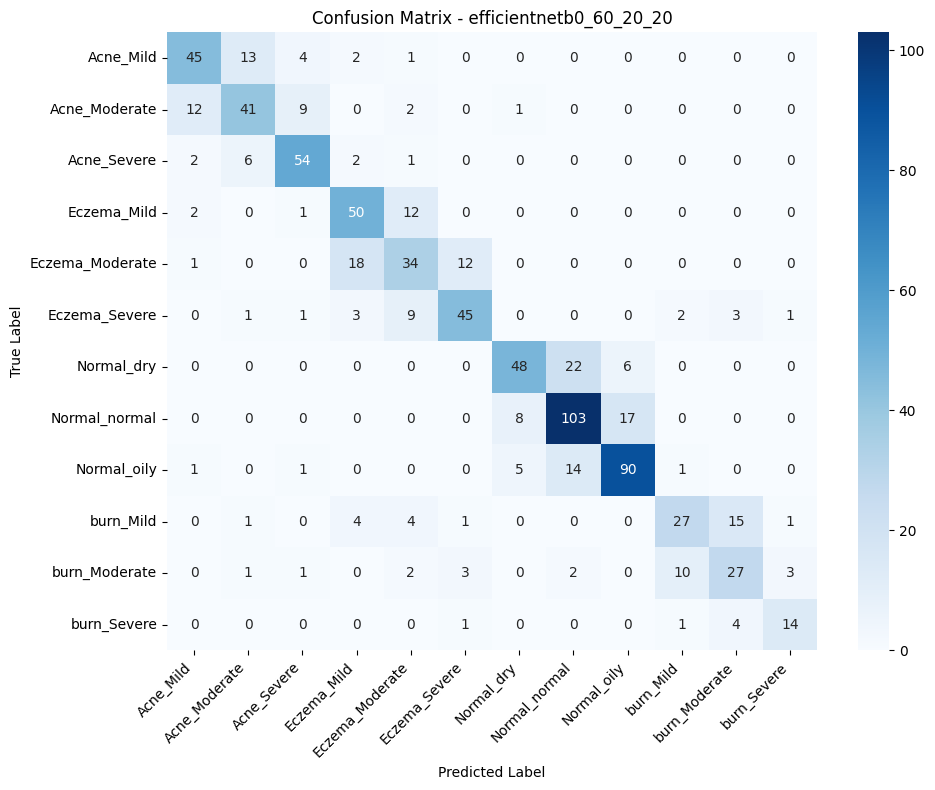

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\efficientnetb0_60_20_20_confusion_matrix.png


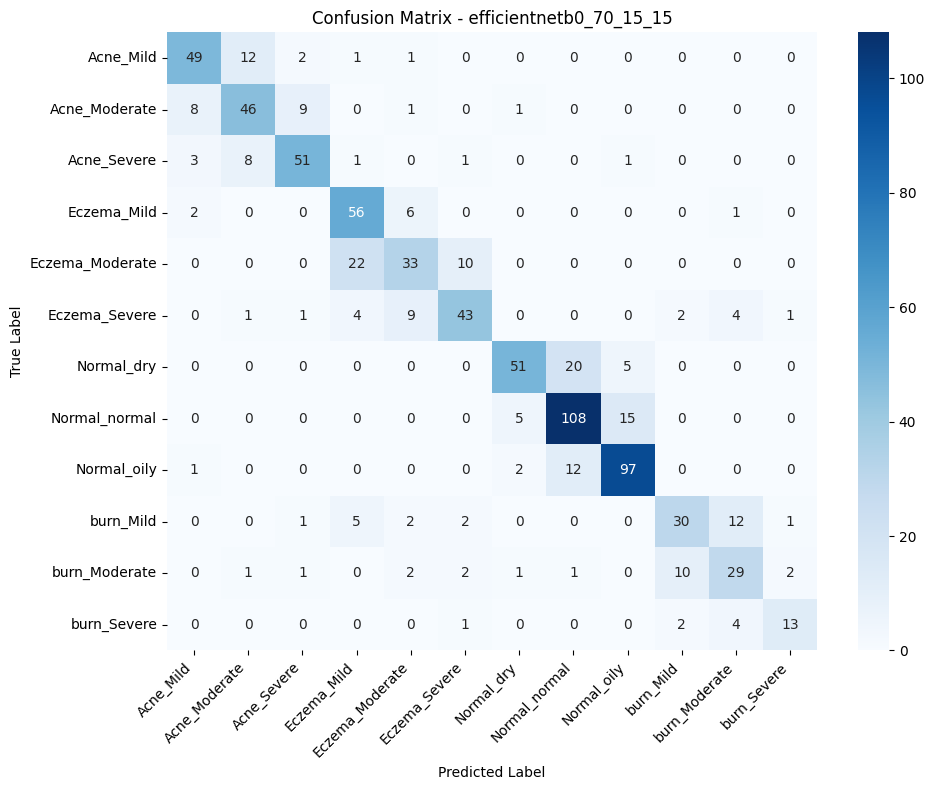

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\efficientnetb0_70_15_15_confusion_matrix.png


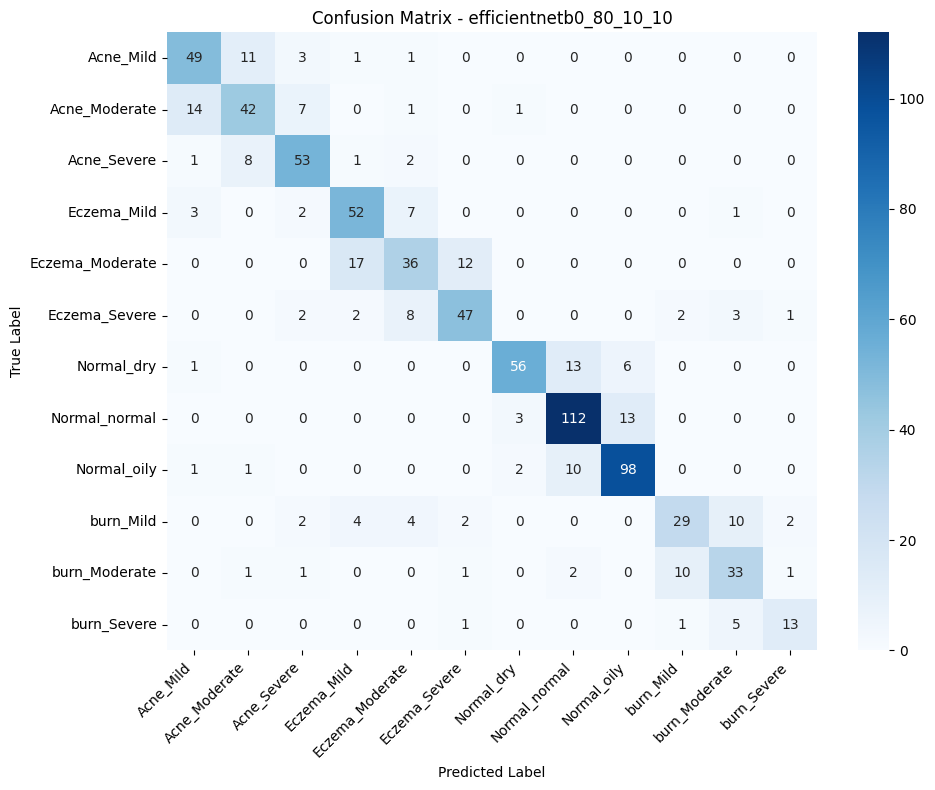

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\efficientnetb0_80_10_10_confusion_matrix.png


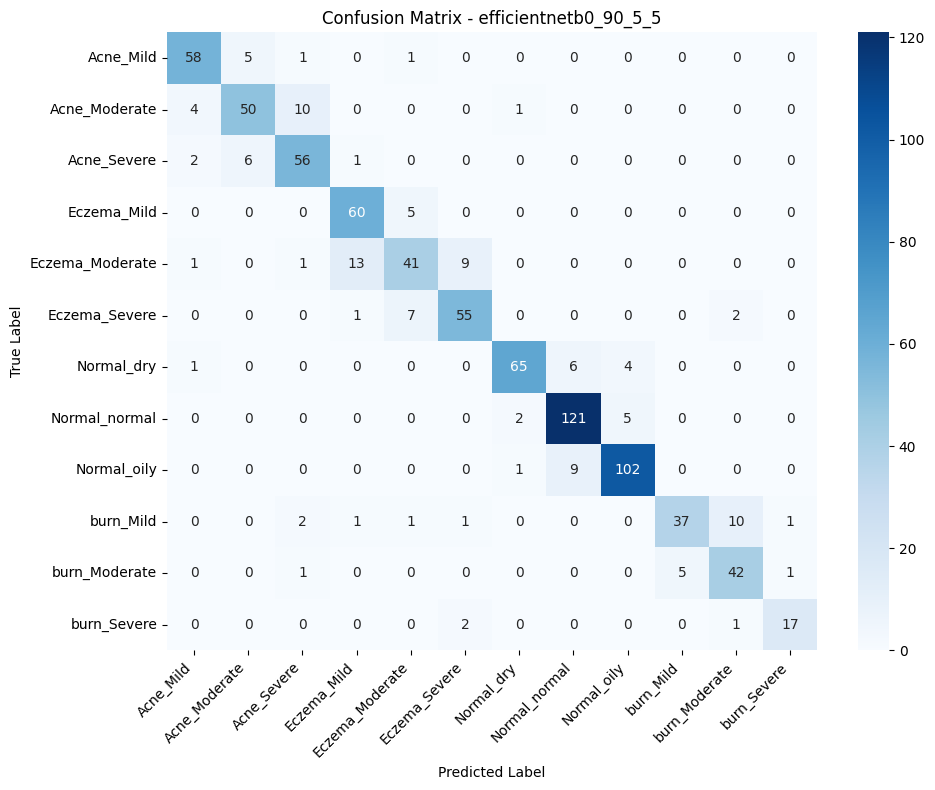

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\efficientnetb0_90_5_5_confusion_matrix.png


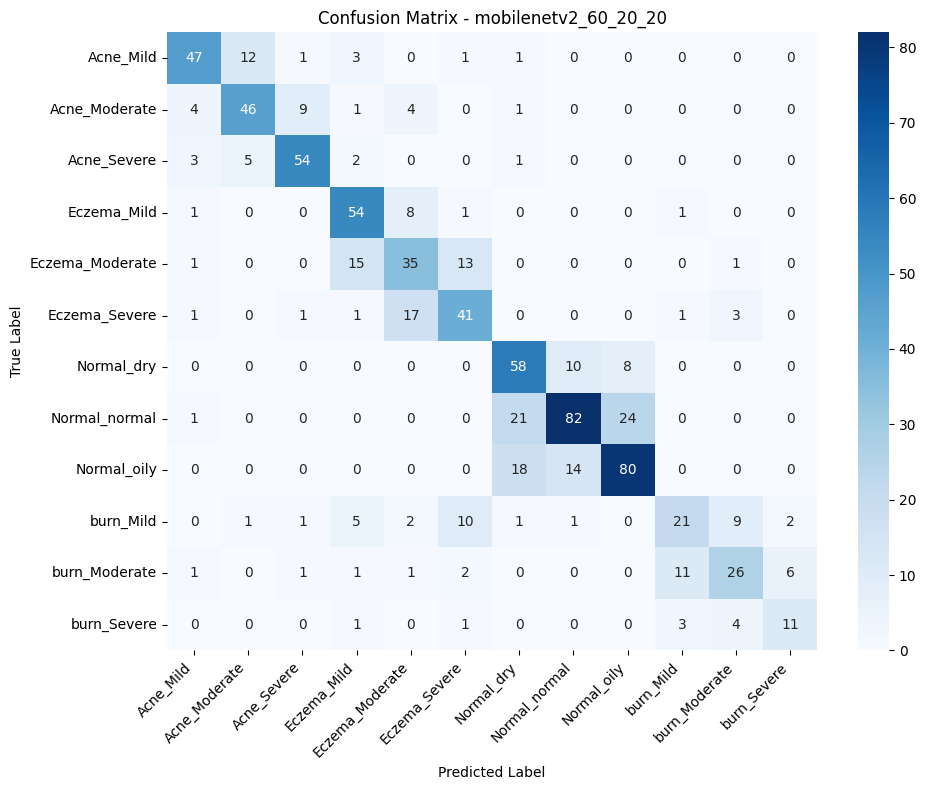

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\mobilenetv2_60_20_20_confusion_matrix.png


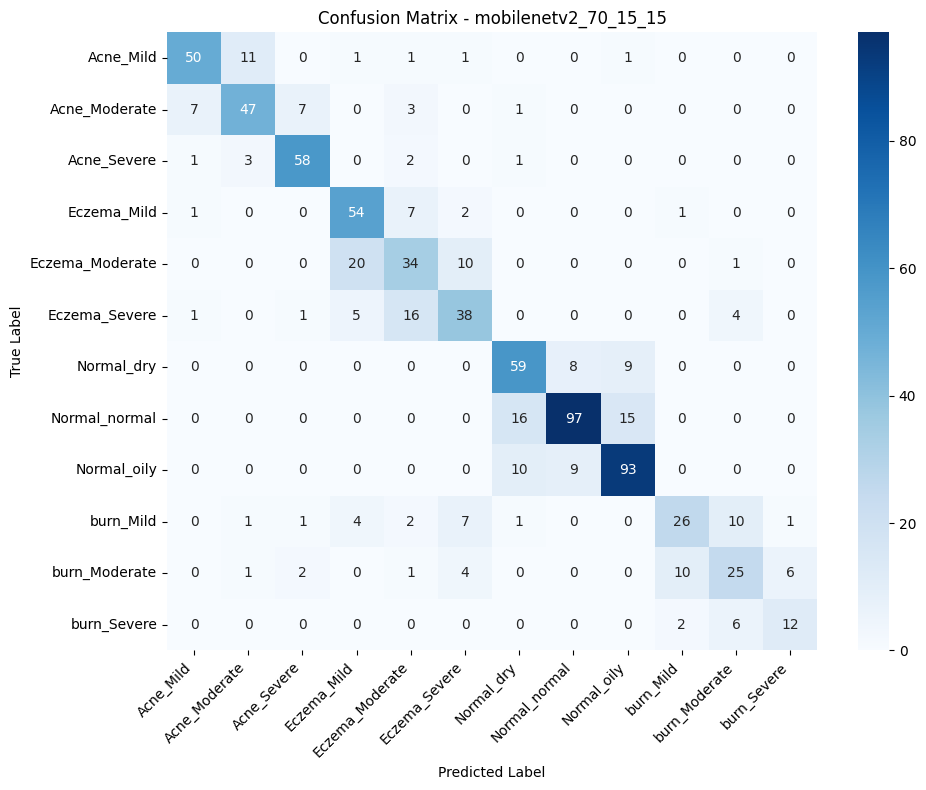

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\mobilenetv2_70_15_15_confusion_matrix.png


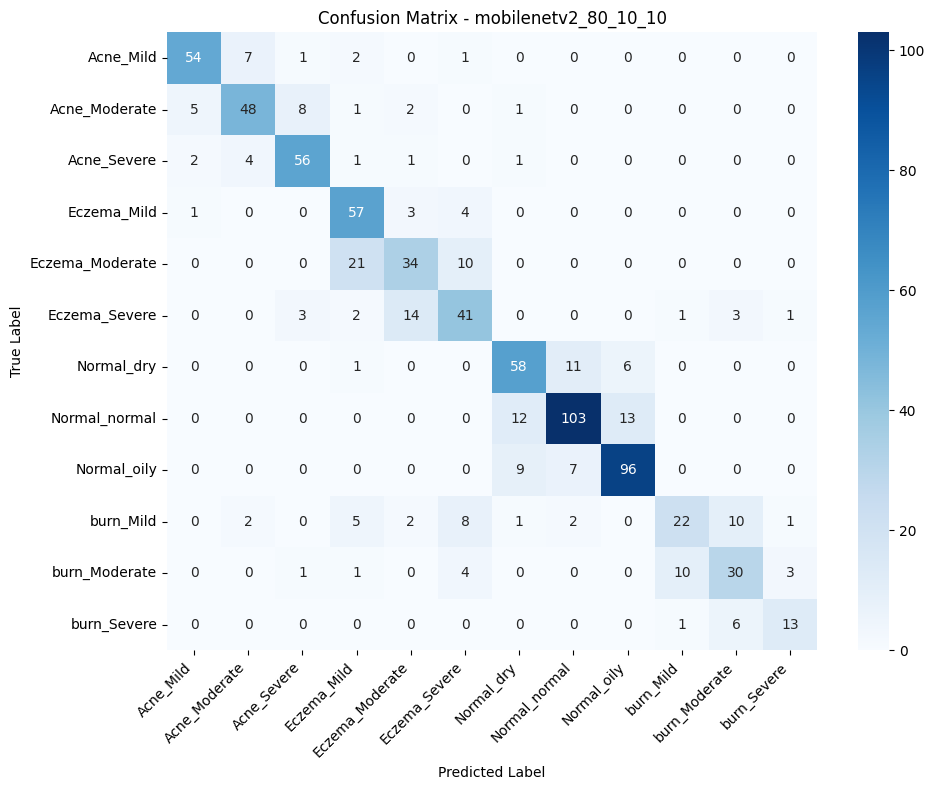

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\mobilenetv2_80_10_10_confusion_matrix.png


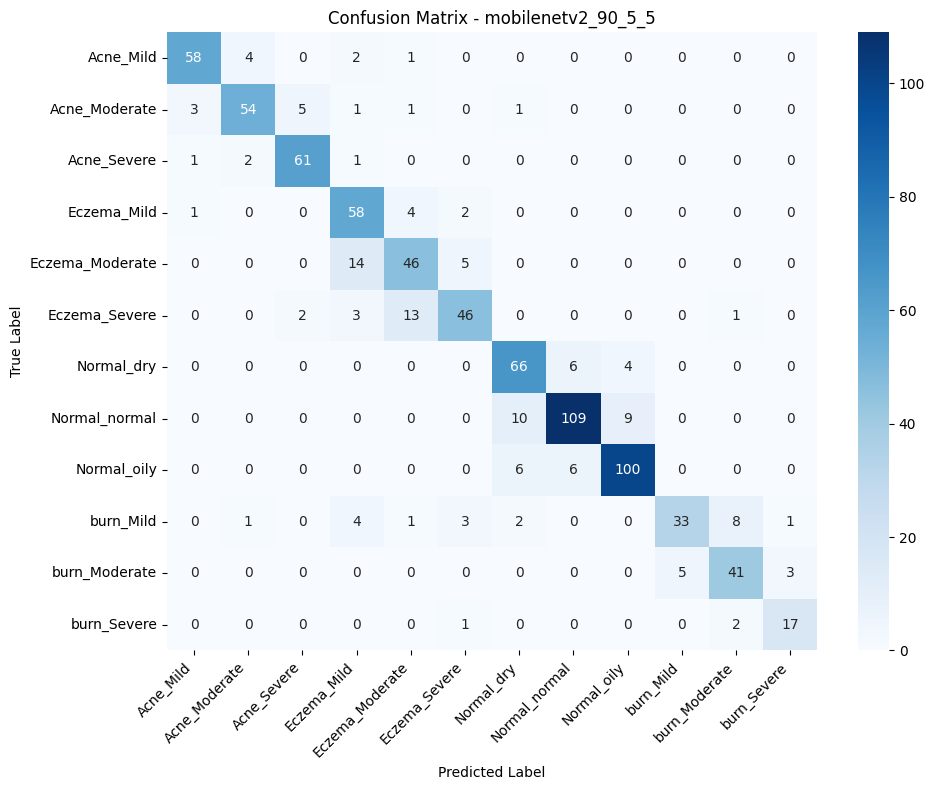

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\mobilenetv2_90_5_5_confusion_matrix.png


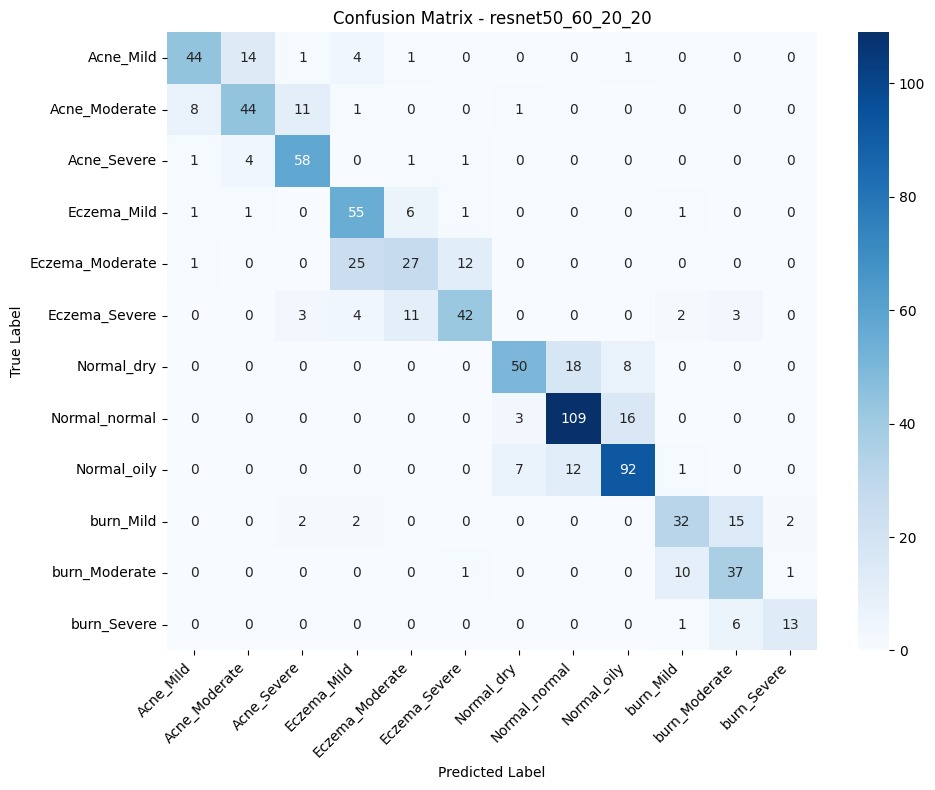

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\resnet50_60_20_20_confusion_matrix.png


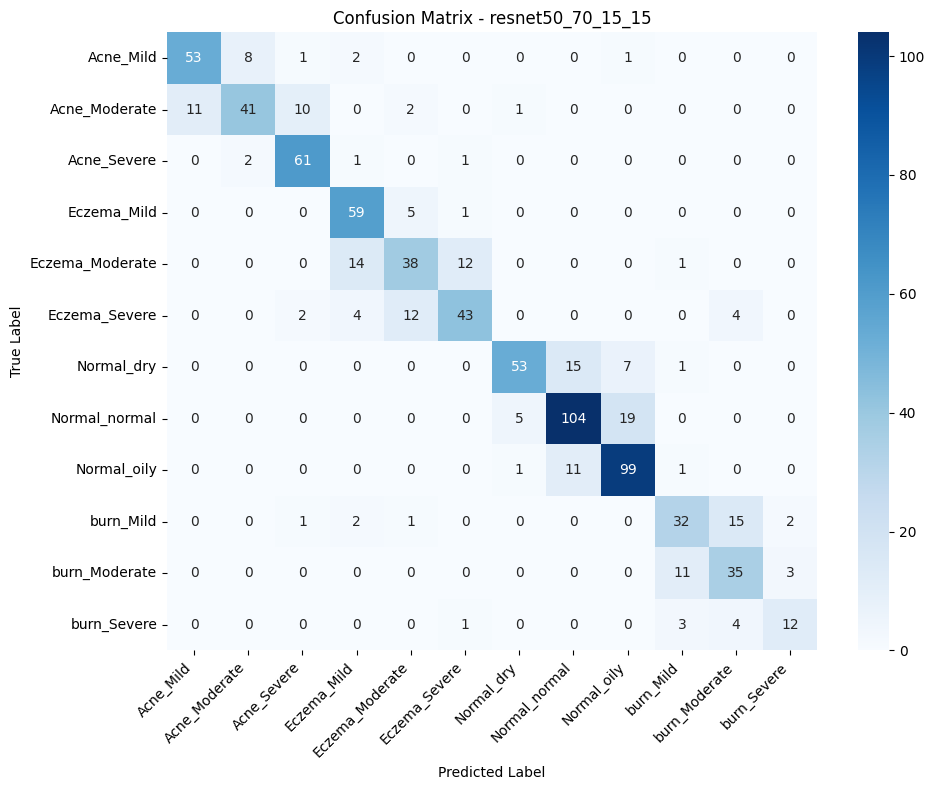

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\resnet50_70_15_15_confusion_matrix.png


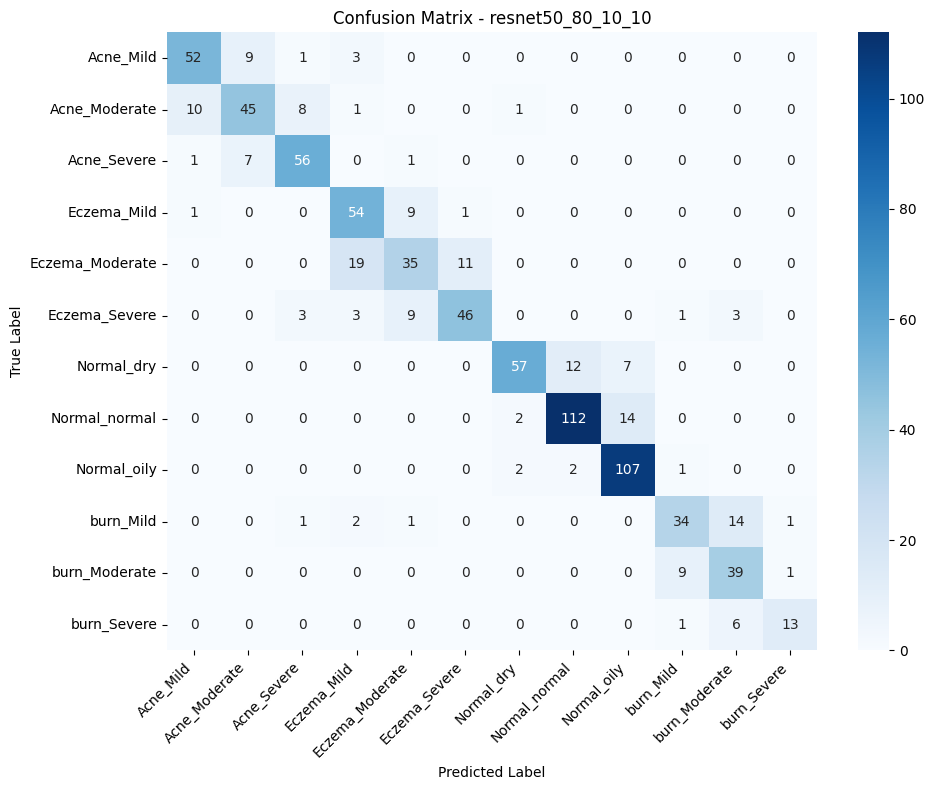

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\resnet50_80_10_10_confusion_matrix.png


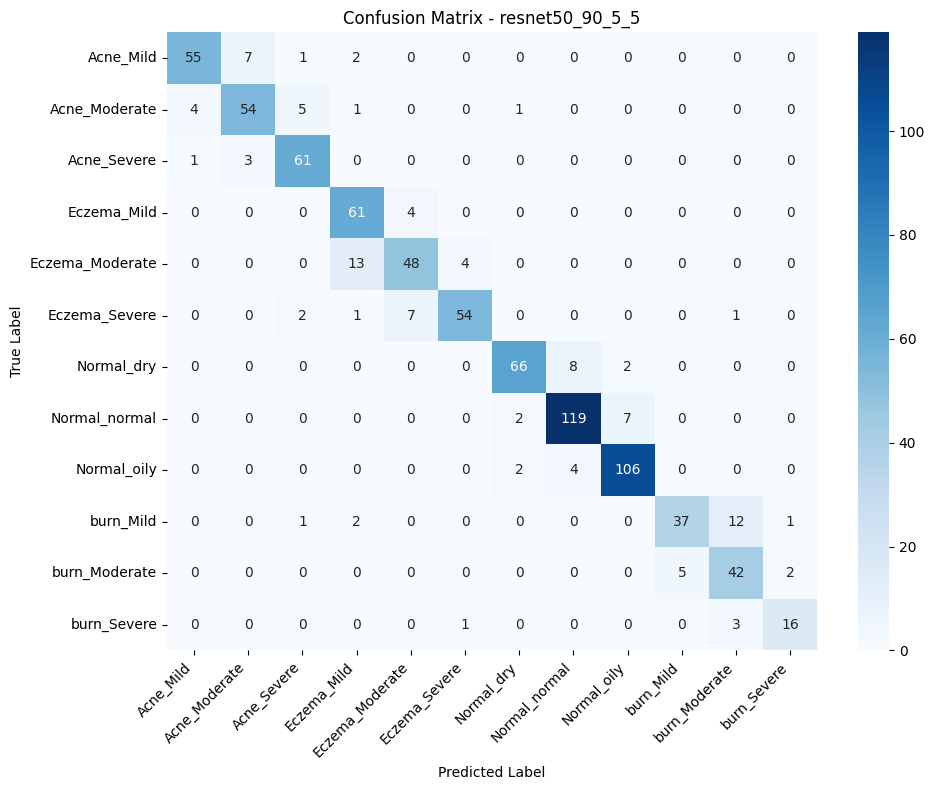

Saved : D:/Brac_thesis\results\comparison\confusion_matrices\resnet50_90_5_5_confusion_matrix.png

All Confusion Matrices Generated Successfully


In [10]:
# ============================================================
# Section 8 : Confusion Matrices
# ============================================================

print("Generating Confusion Matrices...\n")

for model_name in models.keys():

    predicted_labels = predictions[model_name]["predicted_labels"]

    cm = confusion_matrix(

        true_labels,

        predicted_labels

    )

    plt.figure(

        figsize=(10, 8)

    )

    sns.heatmap(

        cm,

        annot=True,

        fmt="d",

        cmap="Blues",

        xticklabels=CLASS_NAMES,

        yticklabels=CLASS_NAMES

    )

    plt.title(

        f"Confusion Matrix - {model_name}"

    )

    plt.xlabel(

        "Predicted Label"

    )

    plt.ylabel(

        "True Label"

    )

    plt.xticks(

        rotation=45,

        ha="right"

    )

    plt.yticks(

        rotation=0

    )

    plt.tight_layout()

    save_path = os.path.join(

        CONFUSION_MATRIX_DIR,

        f"{model_name}_confusion_matrix.png"

    )

    plt.savefig(

        save_path,

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()

    plt.close()

    print(

        f"Saved : {save_path}"

    )

print()

print("All Confusion Matrices Generated Successfully")

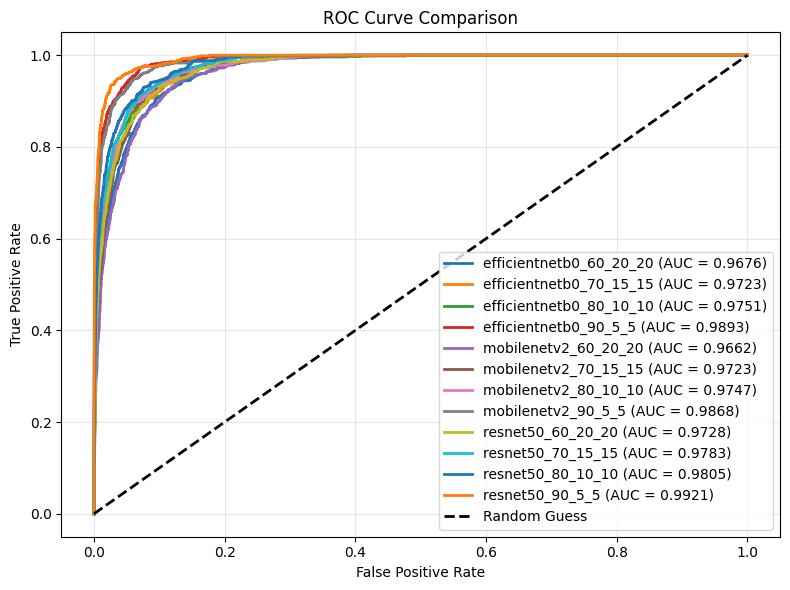

Saved : D:/Brac_thesis\results\comparison\roc_curves\roc_curve_comparison.png


In [11]:
# ============================================================
# Section 9 : ROC Curves
# ============================================================

from sklearn.metrics import roc_curve, auc

plt.figure(

    figsize=(8, 6)

)

for model_name in models.keys():

    probabilities = predictions[model_name][

        "probabilities"

    ]

    fpr, tpr, _ = roc_curve(

        tf.keras.utils.to_categorical(

            true_labels,

            NUM_CLASSES

        ).ravel(),

        probabilities.ravel()

    )

    roc_auc = auc(

        fpr,

        tpr

    )

    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=f"{model_name} (AUC = {roc_auc:.4f})"

    )

plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    linewidth=2,

    color="black",

    label="Random Guess"

)

plt.title(

    "ROC Curve Comparison"

)

plt.xlabel(

    "False Positive Rate"

)

plt.ylabel(

    "True Positive Rate"

)

plt.legend(

    loc="lower right"

)

plt.grid(

    alpha=0.3

)

plt.tight_layout()

save_path = os.path.join(

    ROC_CURVE_DIR,

    "roc_curve_comparison.png"

)

plt.savefig(

    save_path,

    dpi=300,

    bbox_inches="tight"

)

plt.show()

plt.close()

print(f"Saved : {save_path}")

In [12]:
# ============================================================
# Section 10 : Model Performance Comparison
# ============================================================

comparison_df = pd.DataFrame(

    results

)

comparison_df = comparison_df.sort_values(

    by=[

        "Accuracy",

        "F1-Score",

        "ROC-AUC"

    ],

    ascending=False

).reset_index(

    drop=True

)

comparison_df.insert(

    0,

    "Rank",

    np.arange(

        1,

        len(comparison_df) + 1

    )

)

comparison_df = comparison_df.round(

    {

        "Accuracy": 4,

        "Precision": 4,

        "Recall": 4,

        "F1-Score": 4,

        "ROC-AUC": 4,

        "Inference Time (ms/image)": 2

    }

)

comparison_path = os.path.join(

    METRICS_DIR,

    "model_comparison.csv"

)

comparison_df.to_csv(

    comparison_path,

    index=False

)

print("=" * 90)

print("Model Performance Comparison")

print("=" * 90)

display(

    comparison_df

)

print()

print(f"Saved : {comparison_path}")

Model Performance Comparison


,Rank,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Inference Time (ms/image)
0,1,resnet50_90_5_5,0.8684,0.8722,0.8684,0.8679,0.9927,62.86
1,2,efficientnetb0_90_5_5,0.8502,0.8517,0.8502,0.8488,0.9894,24.90
2,3,mobilenetv2_90_5_5,0.8321,0.8371,0.8321,0.8316,0.9872,20.79
3,4,resnet50_80_10_10,0.7850,0.7897,0.7850,0.7834,0.9802,85.18
4,5,resnet50_70_15_15,0.7609,0.7637,0.7609,0.7581,0.9791,70.13
5,6,efficientnetb0_80_10_10,0.7488,0.7498,0.7488,0.7470,0.9749,23.92
6,7,mobilenetv2_80_10_10,0.7391,0.7404,0.7391,0.7359,0.9754,21.06
7,8,efficientnetb0_70_15_15,0.7319,0.7344,0.7319,0.7294,0.9726,24.20
8,9,resnet50_60_20_20,0.7283,0.7316,0.7283,0.7243,0.9723,69.21
9,10,mobilenetv2_70_15_15,0.7162,0.7188,0.7162,0.7146,0.9733,18.77



Saved : D:/Brac_thesis\results\comparison\metrics\model_comparison.csv


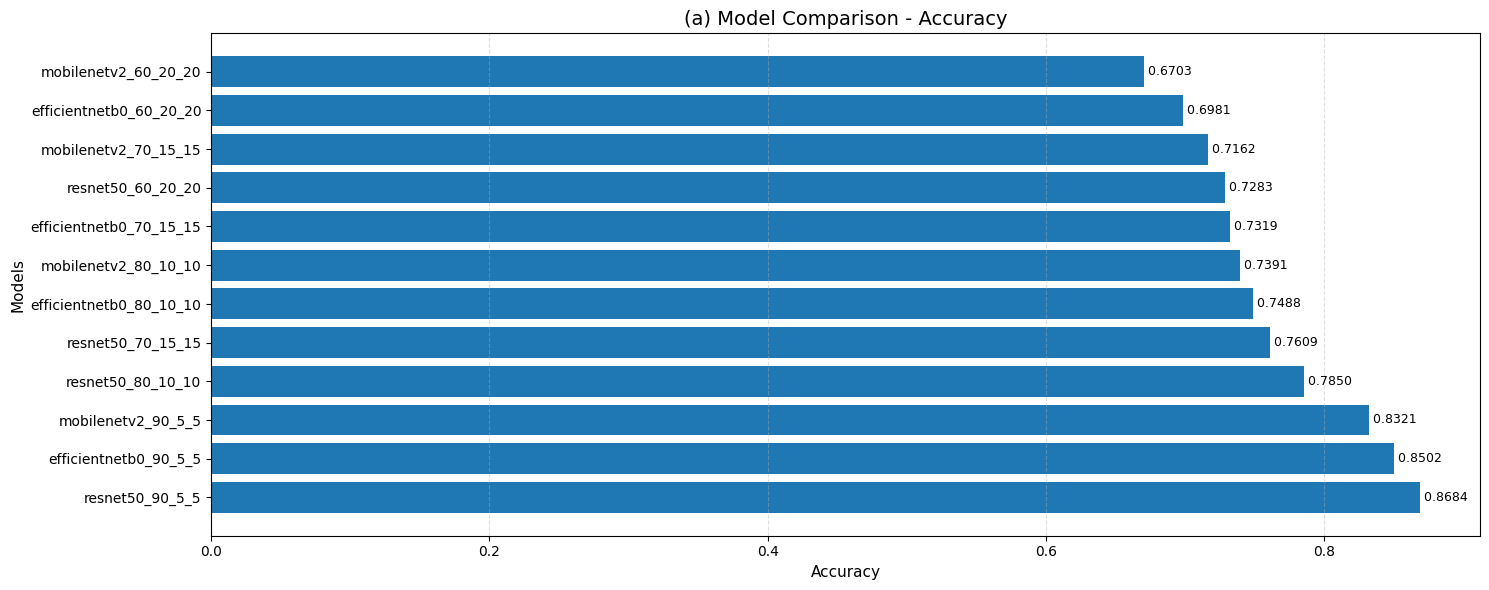

Saved : D:/Brac_thesis\results\comparison\metrics\accuracy.png


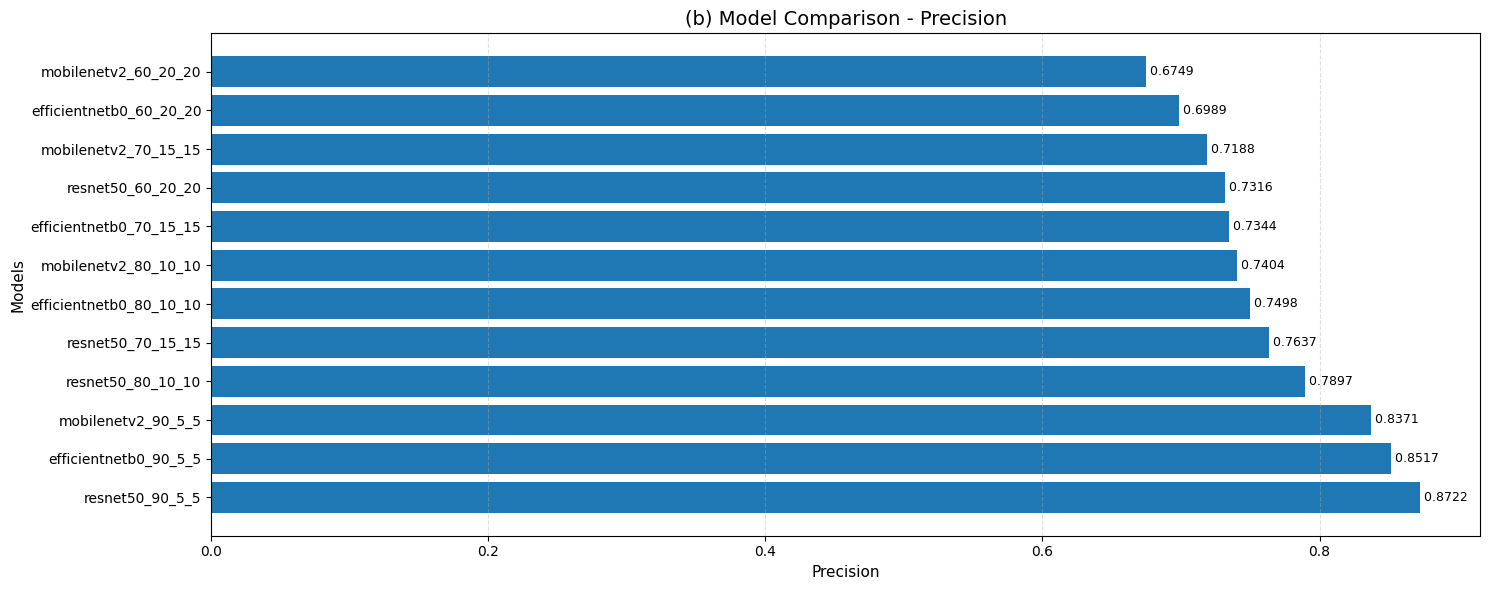

Saved : D:/Brac_thesis\results\comparison\metrics\precision.png


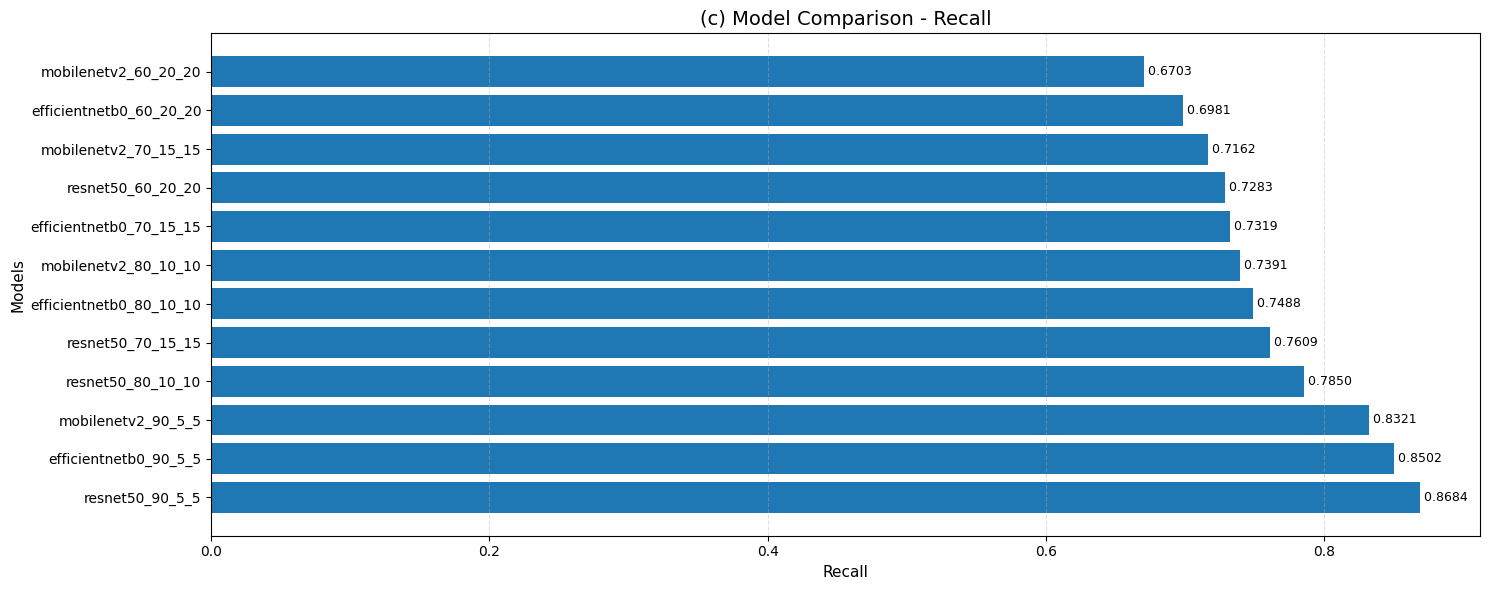

Saved : D:/Brac_thesis\results\comparison\metrics\recall.png


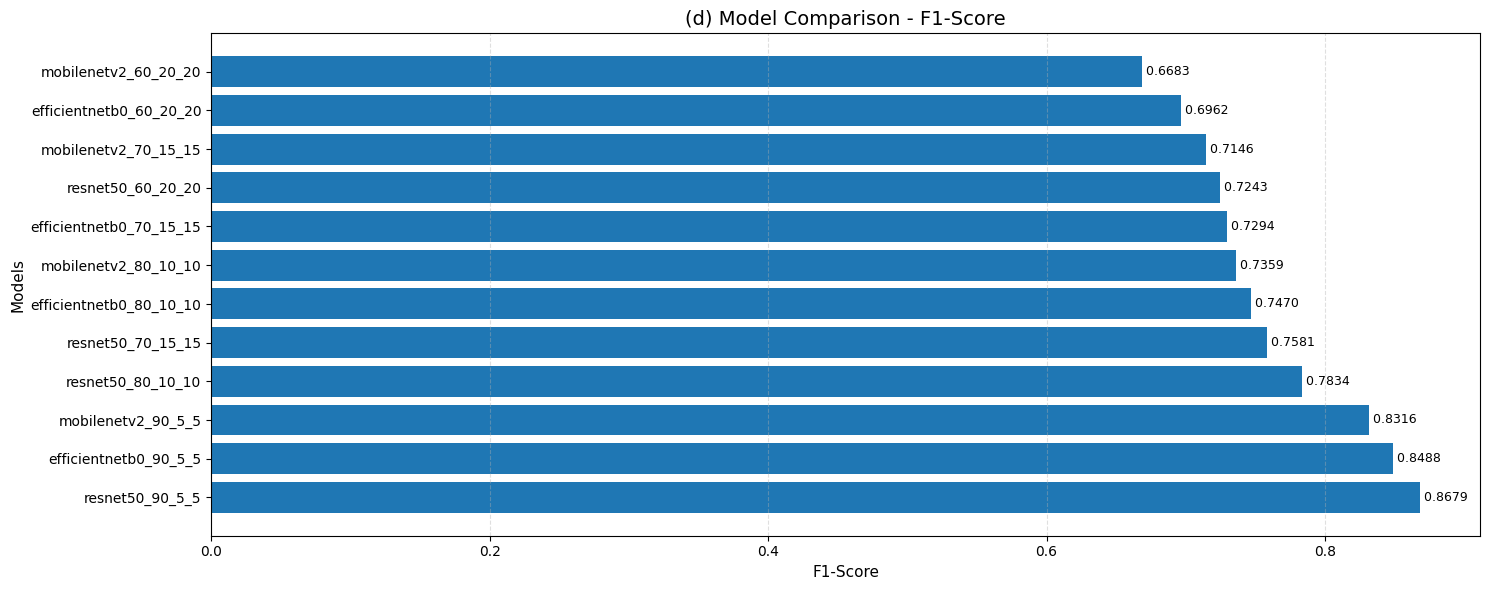

Saved : D:/Brac_thesis\results\comparison\metrics\f1_score.png


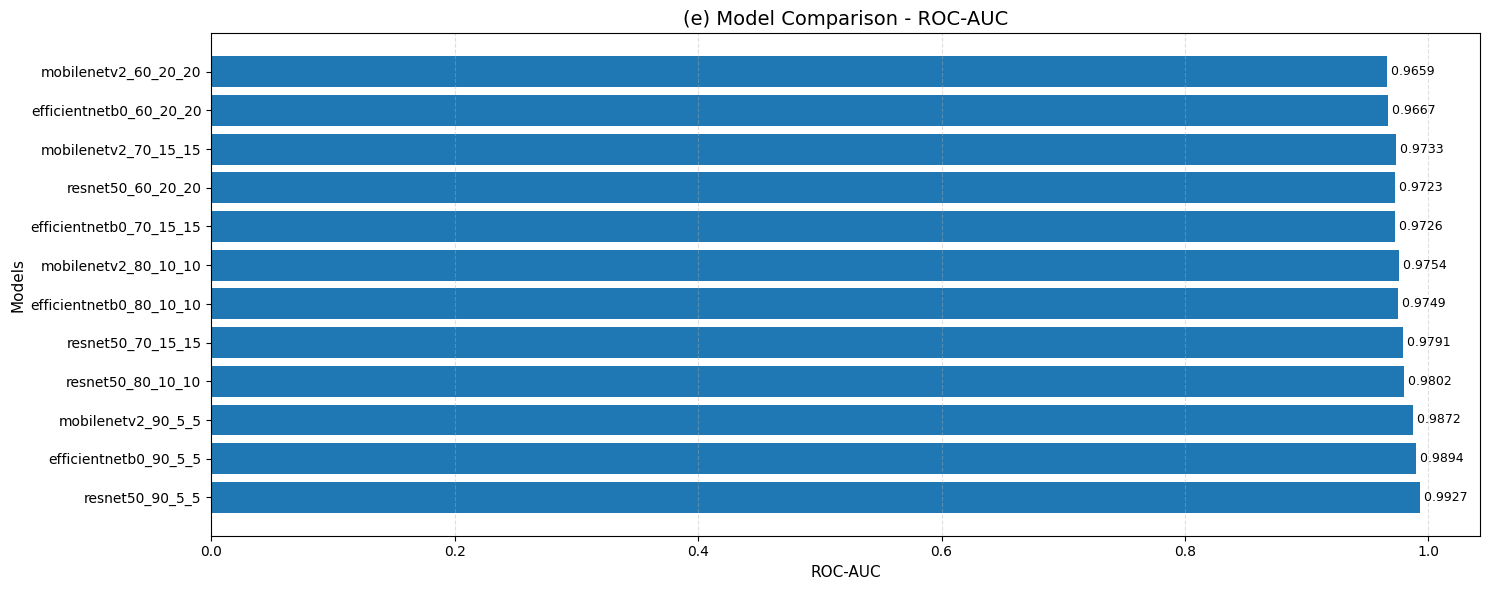

Saved : D:/Brac_thesis\results\comparison\metrics\roc_auc.png


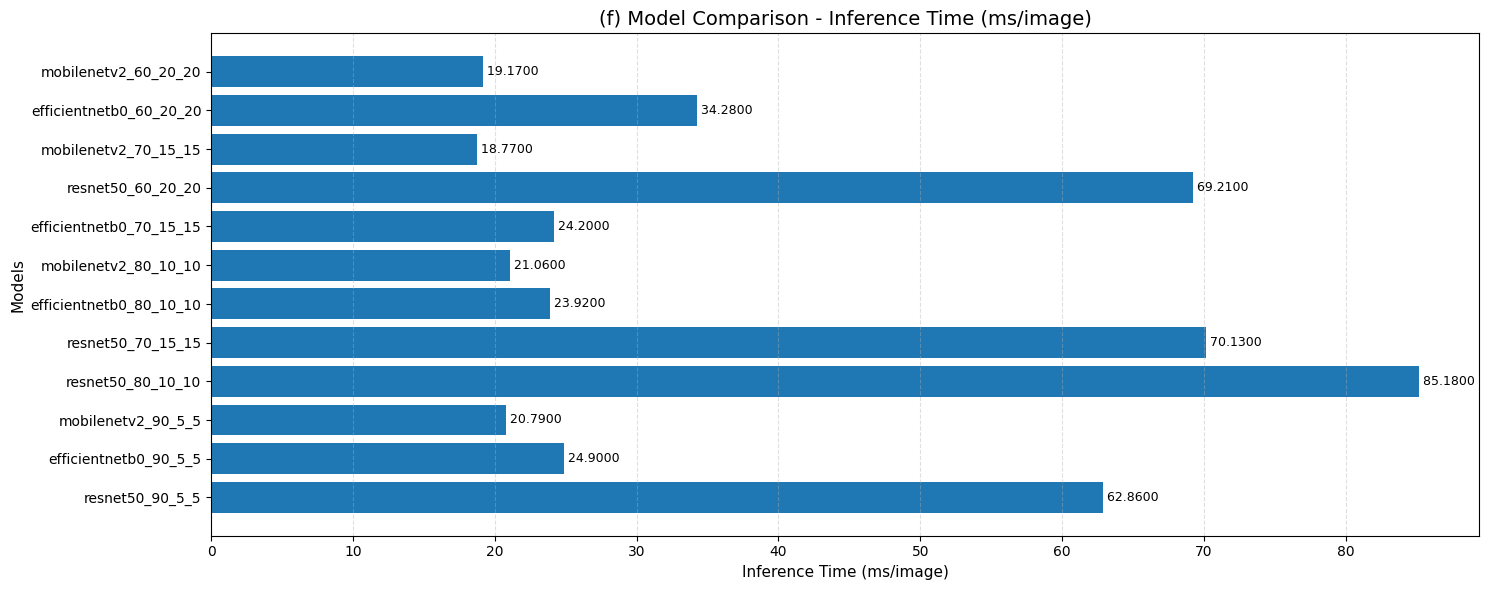

Saved : D:/Brac_thesis\results\comparison\metrics\inference_time_ms_image.png

Performance Visualizations Generated Successfully


In [13]:
# ============================================================
# Section 11 : Performance Visualization
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "Inference Time (ms/image)"
]

# Assign subplot-style labels to each metric
chart_labels = {
    "Accuracy": "(a)",
    "Precision": "(b)",
    "Recall": "(c)",
    "F1-Score": "(d)",
    "ROC-AUC": "(e)",
    "Inference Time (ms/image)": "(f)"
}

for metric in metrics:

    plt.figure(figsize=(15, 6))

    bars = plt.barh(
        comparison_df["Model"],
        comparison_df[metric]
    )

    # --------------------------------------------------------
    # Add letter label to chart title
    # --------------------------------------------------------

    plt.title(
        f"{chart_labels[metric]} Model Comparison - {metric}",
        fontsize=14
    )

    plt.xlabel(
        metric,
        fontsize=11
    )

    plt.ylabel(
        "Models",
        fontsize=11
    )

    # --------------------------------------------------------
    # Keep model names horizontal
    # --------------------------------------------------------

    plt.yticks(
        rotation=0,
        fontsize=10
    )

    plt.grid(
        axis="x",
        linestyle="--",
        alpha=0.4
    )

    # --------------------------------------------------------
    # Show values at the end of bars
    # --------------------------------------------------------

    for bar in bars:

        width = bar.get_width()

        plt.text(
            width,
            bar.get_y() + bar.get_height() / 2,
            f" {width:.4f}",
            ha="left",
            va="center",
            fontsize=9
        )

    plt.tight_layout()

    # --------------------------------------------------------
    # Save each visualization
    # --------------------------------------------------------

    filename = (
        f"{metric.lower().replace(' ', '_')}"
        f"{'_'}"
        f"{metric.lower().replace(' ', '_').replace('-', '_').replace('(', '').replace(')', '').replace('/', '_')}.png"
    )

    # Keep the original filename format
    filename = (
        f"{metric.lower().replace(' ', '_').replace('-', '_').replace('(', '').replace(')', '').replace('/', '_')}.png"
    )

    save_path = os.path.join(
        METRICS_DIR,
        filename
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"Saved : {save_path}")

print()
print("Performance Visualizations Generated Successfully")

In [14]:
# ============================================================
# Section 12 : Best Model Selection
# ============================================================

best_model = comparison_df.iloc[0]

print("=" * 70)

print("BEST MODEL")

print("=" * 70)

print(f"Model Name                : {best_model['Model']}")

print(f"Accuracy                  : {best_model['Accuracy']:.4f}")

print(f"Precision                 : {best_model['Precision']:.4f}")

print(f"Recall                    : {best_model['Recall']:.4f}")

print(f"F1-Score                  : {best_model['F1-Score']:.4f}")

print(f"ROC-AUC                   : {best_model['ROC-AUC']:.4f}")

print(f"Inference Time (ms/image) : {best_model['Inference Time (ms/image)']:.2f}")

print("=" * 70)

# ============================================================
# Save Best Model Information
# ============================================================

best_model_df = pd.DataFrame(

    [best_model]

)

save_path = os.path.join(

    METRICS_DIR,

    "best_model.csv"

)

best_model_df.to_csv(

    save_path,

    index=False

)

print()

print(f"Saved : {save_path}")

BEST MODEL
Model Name                : resnet50_90_5_5
Accuracy                  : 0.8684
Precision                 : 0.8722
Recall                    : 0.8684
F1-Score                  : 0.8679
ROC-AUC                   : 0.9927
Inference Time (ms/image) : 62.86

Saved : D:/Brac_thesis\results\comparison\metrics\best_model.csv


In [15]:
# ============================================================
# Section 14 : Compare Training History
# ============================================================

histories = {}

for model_name in models.keys():

    model_folder, split_folder = model_name.split(

        "_",

        1

    )

    history_path = os.path.join(

        MODELS_DIR,

        model_folder,

        split_folder,

        "training_history.json"

    )

    with open(

        history_path,

        "r"

    ) as file:

        histories[model_name] = json.load(

            file

        )

print(

    "Training Histories Loaded Successfully"

)

Training Histories Loaded Successfully


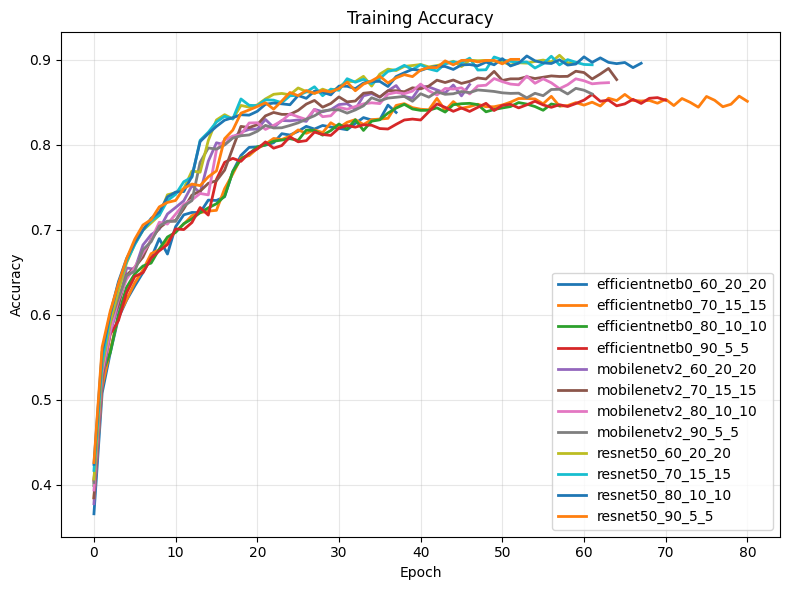

In [16]:
plt.figure(figsize=(8,6))

for model_name, history in histories.items():

    plt.plot(

        history["accuracy"],

        linewidth=2,

        label=model_name

    )

plt.title("Training Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        METRICS_DIR,

        "training_accuracy_comparison.png"

    ),

    dpi=300

)

plt.show()

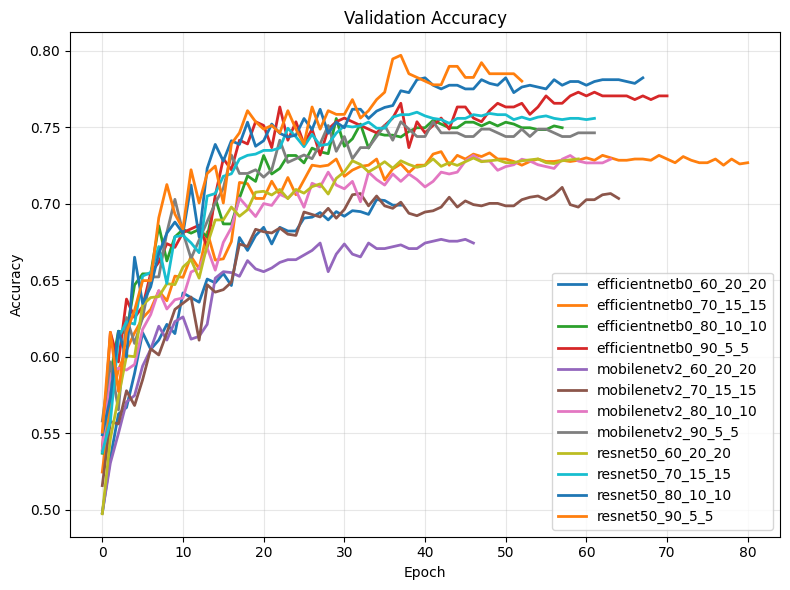

In [17]:
plt.figure(figsize=(8,6))

for model_name, history in histories.items():

    plt.plot(

        history["val_accuracy"],

        linewidth=2,

        label=model_name

    )

plt.title("Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        METRICS_DIR,

        "validation_accuracy_comparison.png"

    ),

    dpi=300

)

plt.show()

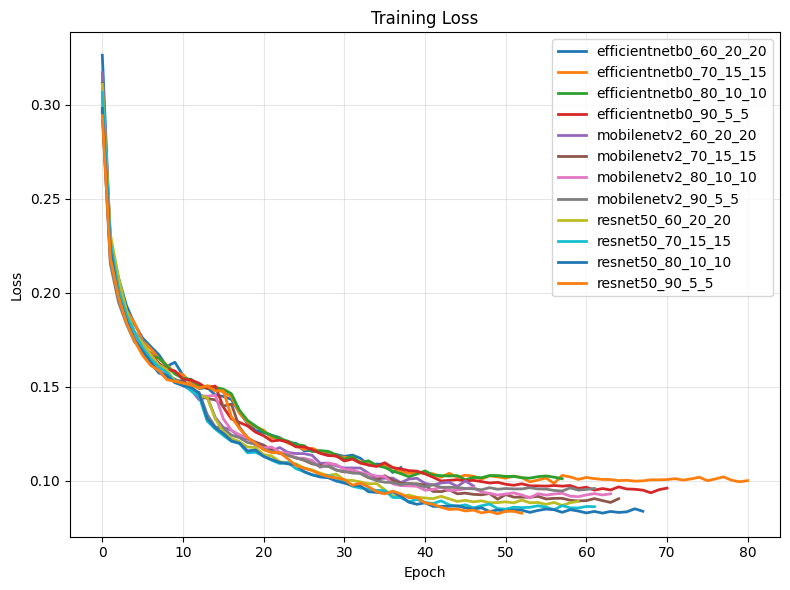

In [18]:
plt.figure(figsize=(8,6))

for model_name, history in histories.items():

    plt.plot(

        history["loss"],

        linewidth=2,

        label=model_name

    )

plt.title("Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        METRICS_DIR,

        "training_loss_comparison.png"

    ),

    dpi=300

)

plt.show()

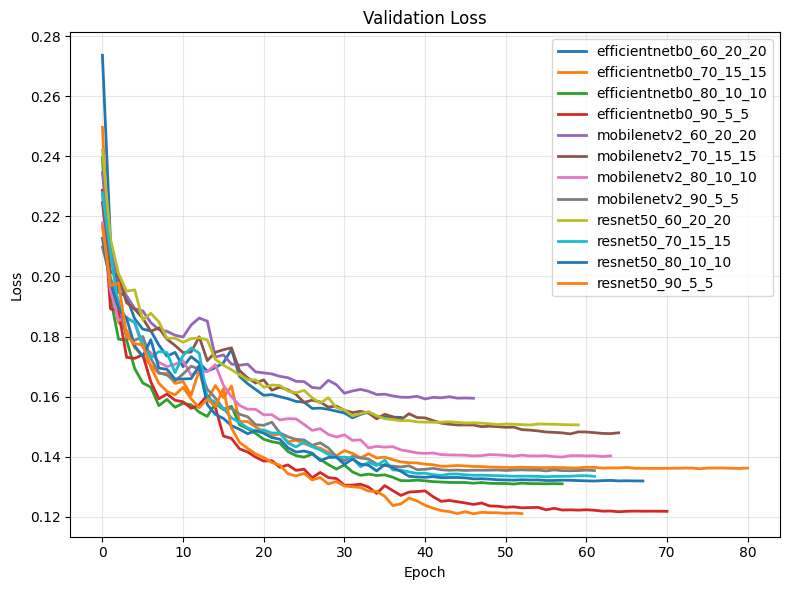

In [19]:
plt.figure(figsize=(8,6))

for model_name, history in histories.items():

    plt.plot(

        history["val_loss"],

        linewidth=2,

        label=model_name

    )

plt.title("Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        METRICS_DIR,

        "validation_loss_comparison.png"

    ),

    dpi=300

)

plt.show()

In [20]:
# ============================================================
# Section 15 : Test Performance Comparison
# ============================================================

test_comparison_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Sort Models by Test Performance
# ------------------------------------------------------------

test_comparison_df = test_comparison_df.sort_values(
    by=[
        "Accuracy",
        "F1-Score",
        "ROC-AUC"
    ],
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Add Model Ranking
# ------------------------------------------------------------

test_comparison_df.insert(
    0,
    "Rank",
    np.arange(1, len(test_comparison_df) + 1)
)

# ------------------------------------------------------------
# Round Metrics
# ------------------------------------------------------------

test_comparison_df = test_comparison_df.round({
    "Accuracy": 4,
    "Precision": 4,
    "Recall": 4,
    "F1-Score": 4,
    "ROC-AUC": 4,
    "Inference Time (ms/image)": 2
})

# ------------------------------------------------------------
# Save Test Comparison
# ------------------------------------------------------------

test_comparison_path = os.path.join(
    METRICS_DIR,
    "test_performance_comparison.csv"
)

test_comparison_df.to_csv(
    test_comparison_path,
    index=False
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=" * 100)
print("TEST PERFORMANCE COMPARISON")
print("=" * 100)

display(test_comparison_df)

print()
print(f"Test Images Evaluated : {len(true_labels)}")
print(f"Models Evaluated      : {len(models)}")
print(f"Results Saved         : {test_comparison_path}")

TEST PERFORMANCE COMPARISON


,Rank,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Inference Time (ms/image)
0,1,resnet50_90_5_5,0.8684,0.8722,0.8684,0.8679,0.9927,62.86
1,2,efficientnetb0_90_5_5,0.8502,0.8517,0.8502,0.8488,0.9894,24.90
2,3,mobilenetv2_90_5_5,0.8321,0.8371,0.8321,0.8316,0.9872,20.79
3,4,resnet50_80_10_10,0.7850,0.7897,0.7850,0.7834,0.9802,85.18
4,5,resnet50_70_15_15,0.7609,0.7637,0.7609,0.7581,0.9791,70.13
5,6,efficientnetb0_80_10_10,0.7488,0.7498,0.7488,0.7470,0.9749,23.92
6,7,mobilenetv2_80_10_10,0.7391,0.7404,0.7391,0.7359,0.9754,21.06
7,8,efficientnetb0_70_15_15,0.7319,0.7344,0.7319,0.7294,0.9726,24.20
8,9,resnet50_60_20_20,0.7283,0.7316,0.7283,0.7243,0.9723,69.21
9,10,mobilenetv2_70_15_15,0.7162,0.7188,0.7162,0.7146,0.9733,18.77



Test Images Evaluated : 828
Models Evaluated      : 12
Results Saved         : D:/Brac_thesis\results\comparison\metrics\test_performance_comparison.csv


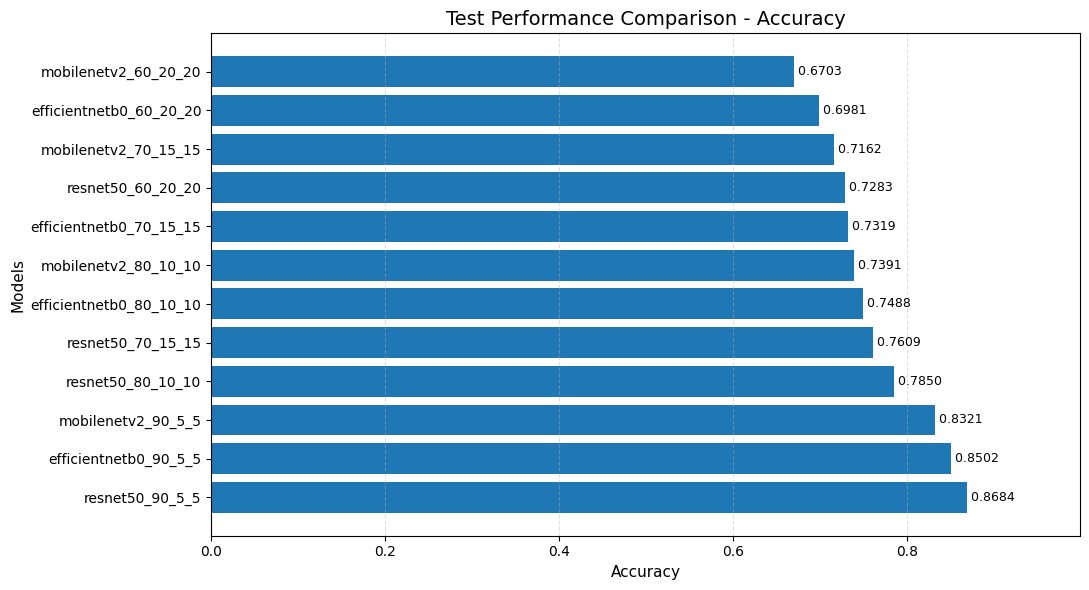

Saved : D:/Brac_thesis\results\comparison\metrics\test_accuracy_comparison.png


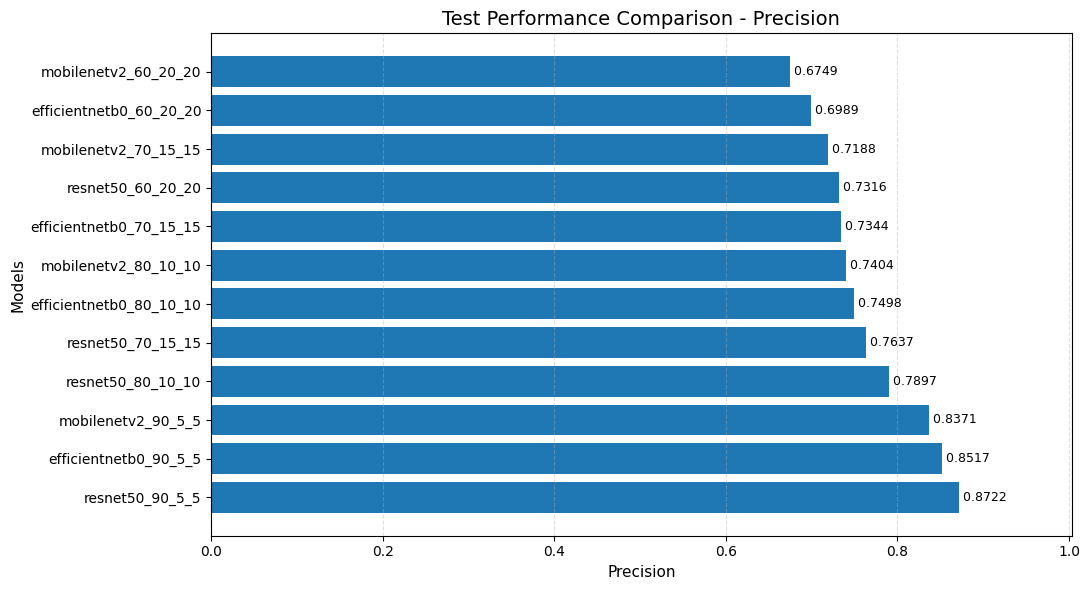

Saved : D:/Brac_thesis\results\comparison\metrics\test_precision_comparison.png


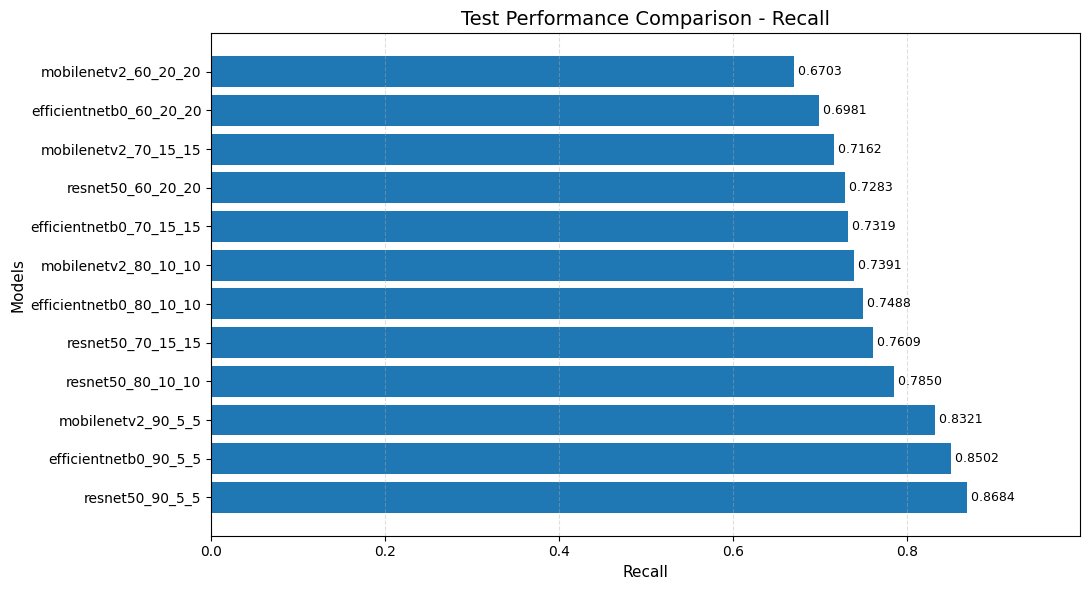

Saved : D:/Brac_thesis\results\comparison\metrics\test_recall_comparison.png


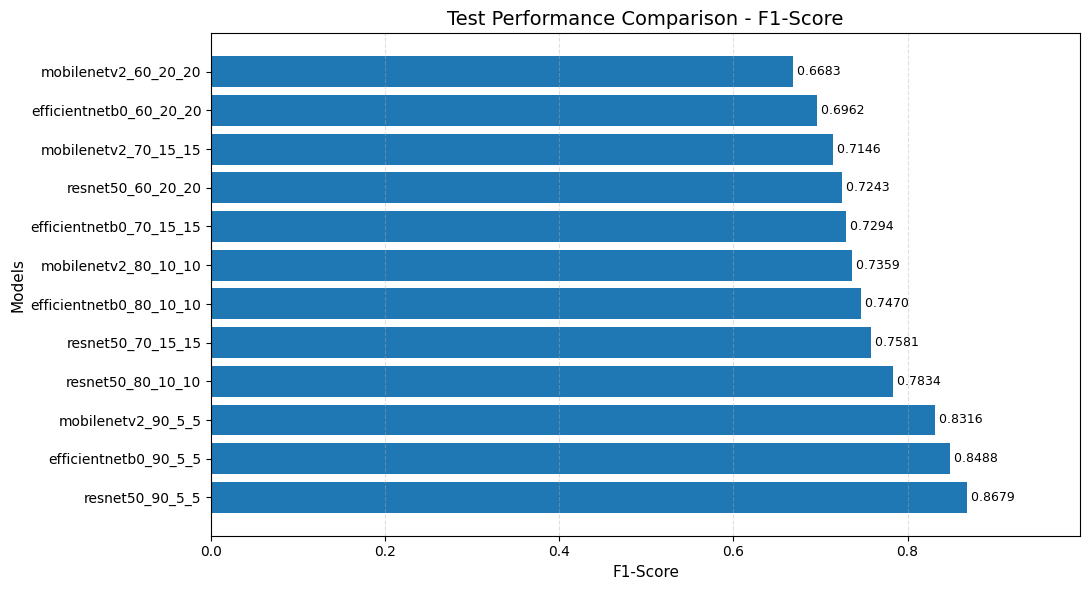

Saved : D:/Brac_thesis\results\comparison\metrics\test_f1_score_comparison.png


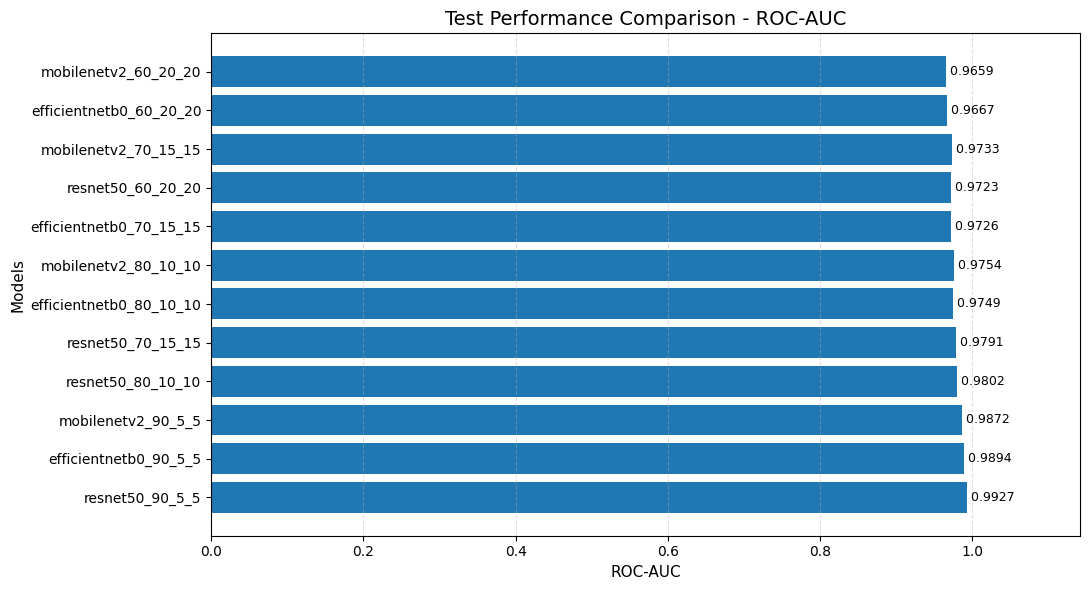

Saved : D:/Brac_thesis\results\comparison\metrics\test_roc_auc_comparison.png


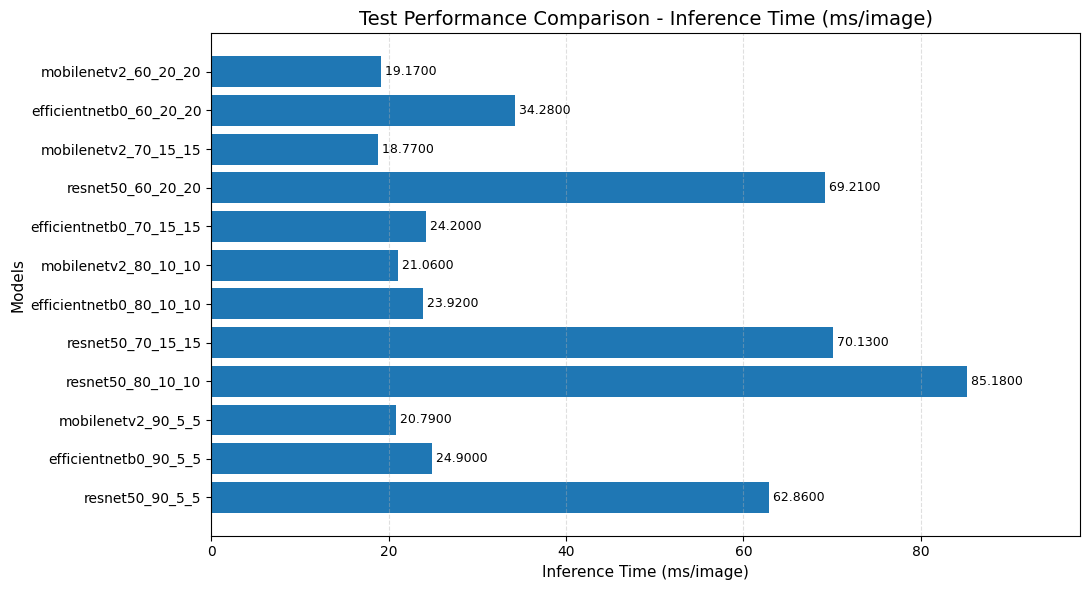

Saved : D:/Brac_thesis\results\comparison\metrics\test_inference_time_ms_image_comparison.png

Test Performance Visualizations Generated Successfully


In [21]:
# ============================================================
# Section 16 : Test Performance Visualization
# ============================================================

test_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "Inference Time (ms/image)"
]

for metric in test_metrics:

    plt.figure(figsize=(11, 6))

    bars = plt.barh(
        test_comparison_df["Model"],
        test_comparison_df[metric]
    )

    # --------------------------------------------------------
    # Chart Titles and Labels
    # --------------------------------------------------------

    plt.title(
        f"Test Performance Comparison - {metric}",
        fontsize=14
    )

    plt.xlabel(metric, fontsize=11)
    plt.ylabel("Models", fontsize=11)

    plt.yticks(
        rotation=0,
        fontsize=10
    )

    plt.grid(
        axis="x",
        linestyle="--",
        alpha=0.4
    )

    # --------------------------------------------------------
    # Display Values on Bars
    # --------------------------------------------------------

    for bar in bars:

        value = bar.get_width()

        plt.text(
            value,
            bar.get_y() + bar.get_height() / 2,
            f" {value:.4f}",
            ha="left",
            va="center",
            fontsize=9
        )

    # --------------------------------------------------------
    # Adjust Chart Limits
    # --------------------------------------------------------

    max_value = test_comparison_df[metric].max()

    plt.xlim(
        0,
        max_value * 1.15 if max_value > 0 else 1
    )

    plt.tight_layout()

    # --------------------------------------------------------
    # Save Chart
    # --------------------------------------------------------

    filename = (
        metric.lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("/", "_")
    )

    save_path = os.path.join(
        METRICS_DIR,
        f"test_{filename}_comparison.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"Saved : {save_path}")

print()
print("Test Performance Visualizations Generated Successfully")

In [22]:
# ============================================================
# Section 17 : Best Model Based on Test Performance
# ============================================================

best_test_model = test_comparison_df.iloc[0]

print("=" * 70)
print("BEST MODEL - TEST DATASET")
print("=" * 70)

print(f"Model Name                : {best_test_model['Model']}")
print(f"Test Accuracy             : {best_test_model['Accuracy']:.4f}")
print(f"Test Precision            : {best_test_model['Precision']:.4f}")
print(f"Test Recall               : {best_test_model['Recall']:.4f}")
print(f"Test F1-Score             : {best_test_model['F1-Score']:.4f}")
print(f"Test ROC-AUC              : {best_test_model['ROC-AUC']:.4f}")
print(
    f"Inference Time (ms/image) : "
    f"{best_test_model['Inference Time (ms/image)']:.2f}"
)

print("=" * 70)

best_test_path = os.path.join(
    METRICS_DIR,
    "best_test_model.csv"
)

pd.DataFrame([best_test_model]).to_csv(
    best_test_path,
    index=False
)

print(f"\nSaved : {best_test_path}")

BEST MODEL - TEST DATASET
Model Name                : resnet50_90_5_5
Test Accuracy             : 0.8684
Test Precision            : 0.8722
Test Recall               : 0.8684
Test F1-Score             : 0.8679
Test ROC-AUC              : 0.9927
Inference Time (ms/image) : 62.86

Saved : D:/Brac_thesis\results\comparison\metrics\best_test_model.csv
